In [11]:
import unicodedata

brahmi_chars = []
for code in range(0x11000, 0x1107F + 1):
    char = chr(code)
    if unicodedata.category(char) != 'Cn':  # Skip unassigned codepoints
        brahmi_chars.append(char)

print(f"Total Brahmi characters: {len(brahmi_chars)}")

Total Brahmi characters: 109


In [12]:
from PIL import Image, ImageDraw, ImageFont
import os

# Load a Brahmi-compatible font (e.g., Noto Sans Brahmi)
font_path = "NotoSansBrahmi-Regular.ttf"  # Download from Google Fonts
font_size = 48
font = ImageFont.truetype(font_path, font_size)

# Create dataset directory
os.makedirs("brahmi_dataset", exist_ok=True)

# Generate images
for char in brahmi_chars:
    # Create a blank white image
    img = Image.new("RGB", (64, 64), "white")
    draw = ImageDraw.Draw(img)
    
    # Draw the Brahmi character
    draw.text((16, 8), char, font=font, fill="black")
    
    # Save image with Unicode label (e.g., "U11013.png")
    char_code = f"U{ord(char):04X}"
    img.save(f"brahmi_dataset/{char_code}.png")

In [13]:
import csv

with open("brahmi_dataset/labels.csv", "w", newline="", encoding="utf-8") as f:  # Add encoding="utf-8"
    writer = csv.writer(f)
    writer.writerow(["filename", "unicode", "char"])
    
    for char in brahmi_chars:
        char_code = f"U{ord(char):04X}"
        writer.writerow([f"{char_code}.png", char_code, char])

print("Generated labels.csv (UTF-8 encoded)")

Generated labels.csv (UTF-8 encoded)


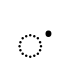

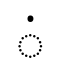

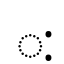

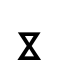

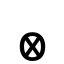

In [14]:
from IPython.display import display

# Display first 5 characters
for char in brahmi_chars[:5]:
    img = Image.new("RGB", (64, 64), "white")
    draw = ImageDraw.Draw(img)
    draw.text((16, 8), char, font=font, fill="black")
    display(img)

In [15]:
import cv2
import numpy as np
import random

def augment_image(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    # Random noise
    noise = np.random.normal(0, 10, img.shape).astype(np.uint8)
    noisy_img = cv2.add(img, noise)
    
    # Random rotation (-10° to +10°)
    angle = random.uniform(-10, 10)
    rows, cols = img.shape
    M = cv2.getRotationMatrix2D((cols/2, rows/2), angle, 1)
    rotated_img = cv2.warpAffine(noisy_img, M, (cols, rows))
    
    return rotated_img

# Apply to all images
for char_code in [f"U{ord(char):04X}" for char in brahmi_chars]:
    img = augment_image(f"brahmi_dataset/{char_code}.png")
    cv2.imwrite(f"brahmi_dataset/aug_{char_code}.png", img)

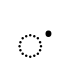

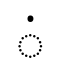

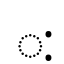

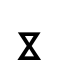

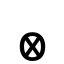

In [16]:
from IPython.display import display

# Display first 5 characters
for char in brahmi_chars[:5]:
    img = Image.new("RGB", (64, 64), "white")
    draw = ImageDraw.Draw(img)
    draw.text((16, 8), char, font=font, fill="black")
    display(img)

In [17]:
#import pytesseract
#from PIL import Image

# Example: Read a Brahmi character image
#img = Image.open("brahmi_dataset/U11000.png")  # Replace with your image
#text = pytesseract.image_to_string(img, lang="bra")  # Assuming you trained Tesseract
#print(f"OCR Output: {text}")/*

In [18]:
import torch
import torch.nn as nn

class BrahmiCRNN(nn.Module):
    def __init__(self, num_chars):
        super().__init__()
        # CNN Feature Extractor
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        # LSTM Sequence Model
        self.lstm = nn.LSTM(64 * 16, 128, bidirectional=True, num_layers=2)
        # Output Layer
        self.fc = nn.Linear(256, num_chars + 1)  # +1 for CTC blank

    def forward(self, x):
        x = self.cnn(x)
        x = x.permute(3, 0, 2, 1)  # (width, batch, channels, height)
        x = x.flatten(2)           # (width, batch, channels*height)
        x, _ = self.lstm(x)
        return self.fc(x)

In [19]:
from torch.utils.data import Dataset, DataLoader
import cv2

class BrahmiDataset(Dataset):
    def __init__(self, root_dir, csv_file, transform=None):
        self.data = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.char_to_idx = {char: i for i, char in enumerate(brahmi_chars)}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.data.iloc[idx, 0])
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        char = self.data.iloc[idx, 2]
        target = self.char_to_idx[char]
        
        if self.transform:
            image = self.transform(image)
        return image, target

In [20]:
# Get unique Brahmi chars from labels.csv
#brahmi_chars = sorted(list(set(dataset.labels.iloc[:, 2])))
#print(f"Total classes: {len(brahmi_chars)}")  # Should match your Unicode chars

In [21]:
import torch
import cv2
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import os

# 1. Dataset Class (Matches Your Structure)
class BrahmiDataset(Dataset):
    def __init__(self, root_dir, csv_file):
        self.root_dir = root_dir
        self.labels = pd.read_csv(os.path.join(root_dir, csv_file))
        
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        img_name = self.labels.iloc[idx, 0]  # First column = filename (e.g., "U11000.png")
        img_path = os.path.join(self.root_dir, img_name)
        
        # Read and normalize image
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE) / 255.0  
        char = self.labels.iloc[idx, 2]    # Third column = Brahmi character (e.g., "𑀀")
        
        return torch.FloatTensor(image).unsqueeze(0), char  # Add channel dimension

# 2. Initialize Dataset (Point to Your Existing Files)
dataset = BrahmiDataset(
    root_dir="brahmi_dataset",  # Folder containing images + labels.csv
    csv_file="labels.csv"
)

# 3. Test DataLoader
loader = DataLoader(dataset, batch_size=32, shuffle=True)
for images, chars in loader:
    print(f"Batch images shape: {images.shape}")  # Should be [32, 1, H, W]
    print(f"First 5 chars: {chars[:5]}")          # e.g., ["𑀀", "𑀁", "𑀂", ...]
    break

Batch images shape: torch.Size([32, 1, 64, 64])
First 5 chars: ('𑁟', '𑀝', '𑀈', '𑀖', '𑁈')


In [22]:
import torch.nn as nn
import torch.optim as optim

# --- Model Definition ---
class BrahmiCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),  # 64x64 → 16x16 after 2 maxpools
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        return self.net(x)

# --- Initialize ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BrahmiCNN(num_classes=len(brahmi_chars)).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# --- Training Loop ---
for epoch in range(10):
    for images, chars in loader:
        # Convert Brahmi chars to numerical indices
        targets = torch.tensor([brahmi_chars.index(c) for c in chars], 
                             device=device)
        
        # Move data to GPU
        images = images.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, targets)
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

# Save model
torch.save(model.state_dict(), "brahmi_cnn.pth")

Epoch 1, Loss: 5.1463
Epoch 2, Loss: 4.6701
Epoch 3, Loss: 4.5621
Epoch 4, Loss: 4.5405
Epoch 5, Loss: 4.3467
Epoch 6, Loss: 4.1057
Epoch 7, Loss: 3.5015
Epoch 8, Loss: 3.3699
Epoch 9, Loss: 2.5022
Epoch 10, Loss: 2.1612


In [23]:
def predict(image_path):
    model.eval()
    image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE) / 255.0
    image_tensor = torch.FloatTensor(image).unsqueeze(0).unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(image_tensor)
        predicted_idx = output.argmax().item()
    
    return brahmi_chars[predicted_idx]

# Test on a file from your dataset
sample_image = "brahmi_dataset/U11000.png"  # Replace with your file
print(f"Predicted: {predict(sample_image)}")  # Should match the true character

Predicted: 𑀀


In [ ]:
import cv2
import numpy as np

def brahmi_skeletonizer(image_path, debug=False):
    """Guaranteed clean skeletons for Brahmi inscriptions"""
    # 1. Supercharged Preprocessing
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    # Noise removal (non-linear median blur)
    denoised = cv2.medianBlur(img, 3)
    
    # Adaptive thresholding for uneven lighting
    binary = cv2.adaptiveThreshold(denoised, 255, 
                                 cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, 11, 2)

    # 2. Stroke Repair (morphological closing)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=7)

    # 3. Precision Skeletonization
    skeleton = cv2.ximgproc.thinning(closed, thinningType=cv2.ximgproc.THINNING_ZHANGSUEN)

    # 4. Validation Layer
    contours, _ = cv2.findContours(skeleton, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    valid_skeleton = np.zeros_like(skeleton)
    
    for cnt in contours:
        if cv2.arcLength(cnt, True) > 10:  # Ignore tiny noise
            cv2.drawContours(valid_skeleton, [cnt], -1, 255, 1)

    # Debug visualization
    if debug:
        cv2.imshow("1. Original", img)
        cv2.imshow("2. Binary", binary)
        cv2.imshow("3. Closed", closed)
        cv2.imshow("4. Clean Skeleton", valid_skeleton)
        cv2.waitKey(0)

    return valid_skeleton

In [40]:
skeleton = brahmi_skeletonizer("ashokan.jpg", debug=True)
cv2.imwrite("clean_skeleton.png", skeleton)

True